# Intelligent Job Recommendation System
## Semantic Matching • Ranking • Recommendation

**Course outcomes covered:** CO1, CO2, CO3 and CO4.

This Colab notebook extends the original real-job-postings recommender without changing its central idea:
**candidate profile/resume → semantic matching → hybrid ranking → explainable job recommendations.**

### Run instructions
1. Open this notebook in Google Colab.
2. Select **Runtime → Change runtime type → T4 GPU** if available (CPU also works, but embeddings may take longer).
3. Run cells from top to bottom, one at a time.
4. When asked, upload a text-based PDF resume (optional). If no resume is uploaded, the example candidate profile is used.
5. For CO4, add a Gemini API key when prompted. The LLM section is optional to execute, but its integration code is included.
6. Keep internet access enabled for dataset/model downloads and the translation/speech cloud services.

**Important:** The notebook uses a public job-postings dataset. The recommender's weighted ranking is a transparent heuristic, not a hiring probability. Review extracted resume information and validate recommendations before presenting results.


## Cell 1 — Install libraries

In [1]:
!pip -q install -U datasets huggingface_hub sentence-transformers scikit-learn pandas numpy matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.5 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [ ]:
%pip install --force-reinstall "numpy==2.2.6" "pandas==2.2.3" "scikit-learn==1.6.1" "bottleneck>=1.5.0"

  Using cached numpy-2.2.6-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (62 kB)
  Using cached pandas-2.2.3-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (89 kB)
  Using cached scikit_learn-1.6.1-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (18 kB)
  Using cached bottleneck-1.6.0-cp313-cp313-manylinux1_x86_64.manylinux_2_28_x86_64.manylinux_2_5_x86_64.whl.metadata (8.2 kB)
  Using cached python_dateutil-3.0.0-py2.py3-none-any.whl.metadata (8.2 kB)
  Using cached pytz-2026.5-py2.py3-none-any.whl.metadata (22 kB)
  Using cached tzdata-2026.5-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached scipy-1.18.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
  Using cached six-1.17.0-py2.py3-none-any

## CO1 dependency — PDF extraction

In [2]:
# CO1 addition: install PDF text extraction library
%pip -q install pymupdf


In [3]:
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from datasets import load_dataset
from sentence_transformers import SentenceTransformer

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("All imports successful!")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


NumPy: 2.4.6
Pandas: 3.1.1
Scikit-learn: 1.9.1
All imports successful!


## Cell 2 — Imports

In [4]:
import os, re, json, ast, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 180)
print("Ready")

Ready


## CO1 Addition A — Extract text from a candidate resume (PDF)

Upload a text-based PDF resume. PyMuPDF extracts text page by page. If the PDF is scanned/image-only, this cell may return little or no text; OCR can be added separately if required.


In [5]:
import fitz  # PyMuPDF

resume_text = ""
resume_filename = None

print("Upload your resume as a PDF. If you do not want to use a resume yet, cancel the upload dialog.")
from google.colab import files
uploaded_resume = files.upload()

pdf_files = [name for name in uploaded_resume if name.lower().endswith(".pdf")]

if pdf_files:
    resume_filename = pdf_files[0]
    pdf_document = fitz.open(stream=uploaded_resume[resume_filename], filetype="pdf")
    resume_pages = [page.get_text("text") for page in pdf_document]
    resume_text = "\n".join(resume_pages).strip()
    pdf_document.close()

    print("Resume:", resume_filename)
    print("Pages extracted:", len(resume_pages))
    print("Characters extracted:", len(resume_text))
    print("\nExtracted text preview:\n")
    print(resume_text[:2000] if resume_text else "No selectable text found. This may be a scanned PDF.")
else:
    print("No PDF uploaded. The notebook will use the editable sample candidate profile in the later cell.")


Upload your resume as a PDF. If you do not want to use a resume yet, cancel the upload dialog.


/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


No PDF uploaded. The notebook will use the editable sample candidate profile in the later cell.


## Cell 3 — Download a real public job-postings dataset

Primary source: Hugging Face dataset repository `MichaelYitzchak/LinkedInJobPostings`. This cell tries the dataset loader first. If that fails because the repository layout or permissions changed, upload a CSV export of the same or another public job-postings dataset when prompted.

For a large dataset, use a GPU runtime and consider sampling a subset first.

In [6]:
DATASET_ID = "MichaelYitzchak/LinkedInJobPostings"
raw_jobs = None

try:
    ds = load_dataset(DATASET_ID)
    print(ds)
    split_name = "train" if "train" in ds else list(ds.keys())[0]
    raw_jobs = ds[split_name].to_pandas()
    print("Loaded split:", split_name, "| shape:", raw_jobs.shape)
except Exception as e:
    print("Automatic dataset load failed:", repr(e))
    print("Upload a real job-postings CSV to continue.")
    from google.colab import files
    uploaded = files.upload()
    csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
    if not csv_files:
        raise ValueError("No CSV uploaded. Upload a public job-postings CSV and rerun this cell.")
    raw_jobs = pd.read_csv(csv_files[0])

print("Columns:", list(raw_jobs.columns))
display(raw_jobs.head(3))

README.md:   0%|          | 0.00/23.5k [00:00<?, ?B/s]

linkedin_postings_sample.csv: reconstructing file:   0%|          |  0.00B /  125MB            

linkedin_postings_sample.csv: downloading bytes:           |  0.00B            

postings.csv.zip: reconstructing file:   0%|          |  0.00B /  154MB            

postings.csv.zip: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/153849 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['job_id', 'company_name', 'title', 'description', 'max_salary', 'pay_period', 'location', 'company_id', 'views', 'med_salary', 'min_salary', 'formatted_work_type', 'applies', 'original_listed_time', 'remote_allowed', 'job_posting_url', 'application_url', 'application_type', 'expiry', 'closed_time', 'formatted_experience_level', 'skills_desc', 'listed_time', 'posting_domain', 'sponsored', 'work_type', 'currency', 'compensation_type', 'normalized_salary', 'zip_code', 'fips'],
        num_rows: 153849
    })
})
Loaded split: train | shape: (153849, 31)
Columns: ['job_id', 'company_name', 'title', 'description', 'max_salary', 'pay_period', 'location', 'company_id', 'views', 'med_salary', 'min_salary', 'formatted_work_type', 'applies', 'original_listed_time', 'remote_allowed', 'job_posting_url', 'application_url', 'application_type', 'expiry', 'closed_time', 'formatted_experience_level', 'skills_desc', 'listed_time', 'posting_domain', 's

,job_id,company_name,title,description,max_salary,pay_period,location,company_id,views,med_salary,...,skills_desc,listed_time,posting_domain,sponsored,work_type,currency,compensation_type,normalized_salary,zip_code,fips
0,3902944011,Current Power,Senior Automation Engineer - Power Systems,"The Senior Automation / Power Systems Engineer will primarily be responsible for the conception, design, development, and implementation of electrical systems. The candidate sh...",NaN,NaN,"Houston, TX",760913.0,22.0,NaN,...,NaN,1.713280e+12,NaN,0,FULL_TIME,NaN,NaN,NaN,77002.0,48201.0
1,3901960222,DISH Network,DISH Installation Technician - Field,"Company Summary\n\nDISH, an EchoStar Company, has been reimagining the future of connectivity for more than 40 years. Our business reach spans satellite television service, liv...",19.75,HOURLY,"Orange, TX",4296.0,5.0,NaN,...,NaN,1.713478e+12,jobs.dish.com,0,FULL_TIME,USD,BASE_SALARY,41080.0,77630.0,48361.0
2,3900944095,"Coca-Cola Bottling Company UNITED, Inc.",Order Builder,"Division: North Alabama\n\nDepartment : Oxford Warehouse Loading\n\nWork Schedule: M-F 8 am UNTIL finished\n\nFrom $34,457 annually\n\nWhy you will love Coca-Cola UNITED?\n\nAb...",NaN,NaN,"Oxford, AL",136791.0,4.0,NaN,...,NaN,1.713389e+12,careers.cokeonena.com,0,FULL_TIME,NaN,NaN,NaN,36203.0,1015.0


## Cell 4 — Detect and standardize dataset fields

This dataset's schema may differ by version. Inspect the printed columns and adjust `COLUMN_MAP` if needed. `job_title` and `job_description` are required. Other columns can remain blank if unavailable.

In [7]:
def find_column(columns, candidates):
    lower_map = {str(c).strip().lower(): c for c in columns}
    for candidate in candidates:
        if candidate.lower() in lower_map:
            return lower_map[candidate.lower()]
    for c in columns:
        cl = str(c).strip().lower()
        if any(candidate.lower() in cl for candidate in candidates):
            return c
    return None

COLUMN_MAP = {
    "job_title": find_column(raw_jobs.columns, ["job_title", "title", "position", "role", "job"]),
    "company": find_column(raw_jobs.columns, ["company", "company_name", "employer", "organization"]),
    "job_description": find_column(raw_jobs.columns, ["job_description", "description", "job_text", "details", "summary", "text"]),
    "skills": find_column(raw_jobs.columns, ["skills", "skills_desc", "required_skills", "skill_set", "technologies", "qualifications"]),
    "experience": find_column(raw_jobs.columns, ["experience", "formatted_experience_level", "experience_level", "years_experience", "experience_required", "seniority"]),
    "location": find_column(raw_jobs.columns, ["location", "city", "job_location", "place"]),
}
print("Detected mapping:", COLUMN_MAP)
if COLUMN_MAP["job_title"] is None or COLUMN_MAP["job_description"] is None:
    raise ValueError(
        "Title/description columns were not detected. Inspect raw_jobs.columns and set "
        "COLUMN_MAP['job_title'] and COLUMN_MAP['job_description'] to exact column names."
    )

jobs = pd.DataFrame()
for target, source in COLUMN_MAP.items():
    jobs[target] = raw_jobs[source].fillna("").astype(str) if source else ""

jobs["job_id"] = np.arange(1, len(jobs)+1)
jobs["job_title"] = jobs["job_title"].str.strip()
jobs["job_description"] = jobs["job_description"].str.strip()
jobs = jobs[(jobs["job_title"] != "") & (jobs["job_description"] != "")]
jobs = jobs.drop_duplicates(subset=["job_title", "company", "job_description"]).reset_index(drop=True)

# Optional sampling for memory/runtime. Set None to use all rows if your runtime can handle it.
MAX_JOBS = 8000  # Faster for a time-limited Colab demo
if MAX_JOBS is not None and len(jobs) > MAX_JOBS:
    jobs = jobs.sample(MAX_JOBS, random_state=SEED).reset_index(drop=True)
jobs["job_id"] = np.arange(1, len(jobs)+1)

print("Usable job postings:", len(jobs))
display(jobs.head())

Detected mapping: {'job_title': 'title', 'company': 'company_name', 'job_description': 'description', 'skills': 'skills_desc', 'experience': 'formatted_experience_level', 'location': 'location'}
Usable job postings: 8000


,job_title,company,job_description,skills,experience,location,job_id
0,DevOps Consultant,Copado,"About Copado:\n\nCopado is the #1 DevOps Platform for Salesforce and the Cloud. We harness the power of native CI/CD and Robotic Testing to drive digital transformation for 1,0...",,Mid-Senior level,"Denver, CO",1
1,Medical Assistant II - Louisville S Dixie,CleanSlate Centers,"Qualifications\n\nWhy You Would Love This Job \n\nYou care. Along with a smile and warm conversation, you can make all the difference to our patients in recovery. As a Medical ...",,Entry level,"Louisville, KY",2
2,Client Services Associate,eTeam,"Job Role - Banker /Client Services AssociateDuration- 12 Months Location- South Jordan, UT Review paper and electronic applications to determine good orderManually process appl...",,Entry level,"South Jordan, UT",3
3,Field Food Service Manager,Circle K,Essential Functions\n\nInnovates the Circle K brand through strategic problem-solving efforts related to our Fresh Food Fast initiatives. Collaborate with Marketing/ Merchandis...,,Mid-Senior level,"Jacksonville, FL",4
4,Retail Sales and Store Support,"Haggen, Inc.","A Day in the Life:\n\nOur sales and store support teams, also known as clerks in the grocery world, play an important part in ensuring our stores are clean, organized, and shop...",,Entry level,"Mount Vernon, WA",5


## Cell 5 — Clean text and parse skill fields

In [8]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9+#.\s/-]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def parse_skills(value):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return []
    s = str(value).strip()
    if not s:
        return []
    if s.startswith("[") and s.endswith("]"):
        try:
            val = ast.literal_eval(s)
            if isinstance(val, (list, tuple, set)):
                return sorted({clean_text(x) for x in val if str(x).strip()})
        except Exception:
            pass
    return sorted({clean_text(x) for x in re.split(r"[,;|\n]", s) if x.strip()})

jobs["skill_list"] = jobs["skills"].map(parse_skills)
jobs["job_text"] = (
    "Job title: " + jobs["job_title"] +
    ". Description: " + jobs["job_description"] +
    ". Skills: " + jobs["skills"] +
    ". Experience: " + jobs["experience"]
)
jobs["clean_job_text"] = jobs["job_text"].map(clean_text)
print("Cleaning complete.")

Cleaning complete.


## CO1 Addition B — Preprocess resume text and extract candidate information

This cell reuses the notebook's existing `clean_text()` function. It detects skills from a transparent keyword list and attempts to identify explicitly stated years of experience. Review the detected values before using them; keyword extraction is not a perfect resume parser.


In [9]:
# Reuse the existing clean_text() function from the preprocessing section.
clean_resume_text = clean_text(resume_text) if resume_text else ""

# A transparent skill vocabulary. Add or remove terms to suit your resume/domain.
RESUME_SKILL_VOCAB = [
    "python", "java", "c++", "c", "sql", "mysql", "mongodb",
    "machine learning", "deep learning", "natural language processing", "nlp",
    "artificial intelligence", "data analysis", "data visualization",
    "tensorflow", "keras", "pytorch", "scikit-learn", "sentence transformers",
    "transformers", "bert", "llm", "generative ai", "prompt engineering",
    "pandas", "numpy", "matplotlib", "seaborn", "flask", "fastapi",
    "django", "spring boot", "node.js", "html", "css", "javascript",
    "react", "git", "github", "docker", "aws", "azure", "gcp",
    "excel", "power bi", "tableau", "statistics", "data structures",
    "algorithms", "rest api", "linux", "iot", "embedded systems"
]

resume_extracted_skills = []
for skill in RESUME_SKILL_VOCAB:
    pattern = r"(?<![a-z0-9])" + re.escape(skill) + r"(?![a-z0-9])"
    if re.search(pattern, clean_resume_text):
        resume_extracted_skills.append(skill)

# Only detect clearly stated experience phrases; manually verify this value.
experience_patterns = [
    r"(\d+(?:\.\d+)?)\s*\+?\s*(?:years?|yrs?)\s+(?:of\s+)?(?:professional\s+)?experience",
    r"experience\s*(?:of|:)\s*(\d+(?:\.\d+)?)\s*\+?\s*(?:years?|yrs?)"
]
experience_matches = []
for pattern in experience_patterns:
    experience_matches.extend(re.findall(pattern, clean_resume_text))

detected_experience_years = float(experience_matches[0]) if experience_matches else None

print("Extracted skills:", resume_extracted_skills)
print("Detected experience (years):", detected_experience_years)
print("\nIMPORTANT: Check these values against your actual resume. You can manually correct them in the candidate profile cell.")


Extracted skills: []
Detected experience (years): None

IMPORTANT: Check these values against your actual resume. You can manually correct them in the candidate profile cell.


## Cell 6 — Inspect dataset quality

Rows: 8000
Missing descriptions: 0
Unique titles: 6797


,job_title,company,location,experience,skills
0,DevOps Consultant,Copado,"Denver, CO",Mid-Senior level,
1,Medical Assistant II - Louisville S Dixie,CleanSlate Centers,"Louisville, KY",Entry level,
2,Client Services Associate,eTeam,"South Jordan, UT",Entry level,
3,Field Food Service Manager,Circle K,"Jacksonville, FL",Mid-Senior level,
4,Retail Sales and Store Support,"Haggen, Inc.","Mount Vernon, WA",Entry level,
5,Physical Therapist - PRN,Interim HealthCare Inc.,"Columbia, SC",,
6,Handyperson,Paths Management Services,"Tulsa, OK",,
7,Civil Graduate Engineer - Transportation,Westwood Professional Services,"Fort Worth, TX",Entry level,
8,Operator Technician - Raw/FG,Blue Diamond Growers,"Turlock, CA",Entry level,
9,Administrative Assistant - Estimating,"Bay Cities Paving & Grading, Inc.","Concord, CA",Associate,


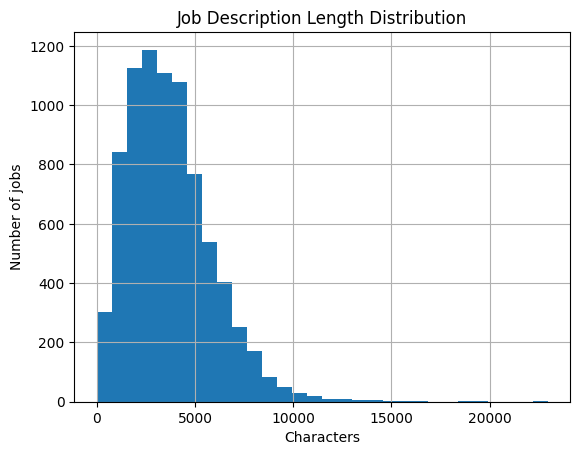

In [10]:
print("Rows:", len(jobs))
print("Missing descriptions:", (jobs["job_description"].str.strip() == "").sum())
print("Unique titles:", jobs["job_title"].nunique())
display(jobs[["job_title","company","location","experience","skills"]].head(10))
jobs["description_length"] = jobs["job_description"].str.len()
jobs["description_length"].hist(bins=30)
plt.title("Job Description Length Distribution")
plt.xlabel("Characters")
plt.ylabel("Number of jobs")
plt.show()

## Cell 7 — TF-IDF baseline

In [11]:
tfidf_vectorizer = TfidfVectorizer(
    stop_words="english", ngram_range=(1,2), max_features=100000, min_df=1
)
job_tfidf_matrix = tfidf_vectorizer.fit_transform(jobs["clean_job_text"])
print("TF-IDF matrix shape:", job_tfidf_matrix.shape)

TF-IDF matrix shape: (8000, 100000)


## Cell 8 — Semantic embeddings

In [12]:
MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
model = SentenceTransformer(MODEL_NAME)

job_embeddings = model.encode(
    jobs["job_text"].tolist(),
    batch_size=64,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)
print("Embedding matrix:", job_embeddings.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/125 [00:00<?, ?it/s]

Embedding matrix: (8000, 384)


## Cell 9 — Define candidate profile
Edit this profile to test different candidates. The current values are an example profile, not a real person's data.

In [13]:
# Candidate profile: use extracted resume details when available.
# You can manually add skills or correct experience below.

EXTRA_CANDIDATE_SKILLS = []  # Example: ["Python", "SQL"]
MANUAL_EXPERIENCE_YEARS = None  # Set a number if automatic detection is incorrect.
PREFERRED_ROLES = ["NLP Engineer", "Machine Learning Engineer", "AI Engineer"]
PREFERRED_LOCATION = "Remote"

if resume_text.strip():
    candidate_summary = resume_text[:1500]
    base_skills = resume_extracted_skills
else:
    # Fallback profile so the original recommendation workflow still runs without a PDF.
    candidate_summary = (
        "Computer Science student interested in NLP, machine learning, "
        "semantic search and AI engineering."
    )
    base_skills = [
        "Python", "Machine Learning", "NLP", "Deep Learning",
        "TensorFlow", "SQL", "Sentence Transformers"
    ]

candidate_skills_for_profile = sorted(set(base_skills + EXTRA_CANDIDATE_SKILLS))

if MANUAL_EXPERIENCE_YEARS is not None:
    candidate_experience_years = float(MANUAL_EXPERIENCE_YEARS)
elif detected_experience_years is not None:
    candidate_experience_years = float(detected_experience_years)
else:
    candidate_experience_years = 0.0

candidate_profile = {
    "summary": candidate_summary,
    "skills": candidate_skills_for_profile,
    "experience_years": candidate_experience_years,
    "preferred_roles": PREFERRED_ROLES,
    "preferred_location": PREFERRED_LOCATION
}

print("Candidate profile prepared:")
print("Skills:", candidate_profile["skills"])
print("Experience years:", candidate_profile["experience_years"])
print("Preferred roles:", candidate_profile["preferred_roles"])
print("Summary preview:", candidate_profile["summary"][:300])


Candidate profile prepared:
Skills: ['Deep Learning', 'Machine Learning', 'NLP', 'Python', 'SQL', 'Sentence Transformers', 'TensorFlow']
Experience years: 0.0
Preferred roles: ['NLP Engineer', 'Machine Learning Engineer', 'AI Engineer']
Summary preview: Computer Science student interested in NLP, machine learning, semantic search and AI engineering.


## Cell 10 — Candidate text

In [14]:
def normalize_skill_list(skills):
    if isinstance(skills, str):
        skills = parse_skills(skills)
    return sorted({clean_text(s) for s in (skills or []) if str(s).strip()})

def build_candidate_text(profile):
    skills = normalize_skill_list(profile.get("skills", []))
    roles = profile.get("preferred_roles", [])
    if isinstance(roles, str):
        roles = [roles]
    return (
        f"Candidate summary: {profile.get('summary','')}. "
        f"Skills: {', '.join(skills)}. Preferred roles: {', '.join(roles)}. "
        f"Experience: {profile.get('experience_years',0)} years."
    )

candidate_text = build_candidate_text(candidate_profile)
candidate_skills = normalize_skill_list(candidate_profile.get("skills", []))
print(candidate_text)

Candidate summary: Computer Science student interested in NLP, machine learning, semantic search and AI engineering.. Skills: deep learning, machine learning, nlp, python, sentence transformers, sql, tensorflow. Preferred roles: NLP Engineer, Machine Learning Engineer, AI Engineer. Experience: 0.0 years.


## CO1 Addition C — Vectorize the candidate profile

The job descriptions have already been vectorized in the existing TF-IDF and Sentence Transformer cells. This cell transforms the candidate profile using those same fitted components, so the candidate and jobs can be compared in a shared vector space. The existing recommendation function will continue to use the candidate profile and the stored job embeddings.


In [15]:
candidate_text = build_candidate_text(candidate_profile)

# Transform candidate text with the already-fitted TF-IDF vectorizer.
candidate_tfidf_vector = tfidf_vectorizer.transform([clean_text(candidate_text)])

# Encode candidate text with the already-loaded Sentence Transformer.
candidate_embedding = model.encode(
    [candidate_text],
    convert_to_numpy=True,
    normalize_embeddings=True
)

print("Candidate TF-IDF shape:", candidate_tfidf_vector.shape)
print("Candidate semantic embedding shape:", candidate_embedding.shape)
print("Job TF-IDF shape:", job_tfidf_matrix.shape)
print("Job embeddings shape:", job_embeddings.shape)

# Basic dimensionality checks before recommendation.
assert candidate_tfidf_vector.shape[1] == job_tfidf_matrix.shape[1], "TF-IDF dimensions do not match."
assert candidate_embedding.shape[1] == job_embeddings.shape[1], "Embedding dimensions do not match."

print("CO1 candidate vectorization completed successfully.")


Candidate TF-IDF shape: (1, 100000)
Candidate semantic embedding shape: (1, 384)
Job TF-IDF shape: (8000, 100000)
Job embeddings shape: (8000, 384)
CO1 candidate vectorization completed successfully.


## Cell 11 — Skill overlap

In [16]:
def calculate_skill_match(candidate_skills, job_skill_list, job_text=""):
    cand = set(normalize_skill_list(candidate_skills))
    jobset = set(normalize_skill_list(job_skill_list))
    if not jobset:
        text = clean_text(job_text)
        # Conservative exact phrase matching against description
        jobset = {s for s in cand if s and re.search(r"(?<!\w)" + re.escape(s) + r"(?!\w)", text)}
    matched = sorted(cand & jobset)
    missing = sorted(jobset - cand)
    score = len(matched) / max(1, len(cand))
    return float(score), matched, missing

## Cell 12 — Experience compatibility heuristic

In [17]:
def parse_min_experience(value):
    s = clean_text(value)
    if not s:
        return None
    if any(t in s for t in ["intern", "entry level", "fresher", "no experience", "graduate", "junior"]):
        return 0.0
    plus = re.search(r"(\d+(?:\.\d+)?)\s*\+", s)
    if plus:
        return float(plus.group(1))
    rng = re.search(r"(\d+(?:\.\d+)?)\s*(?:-|to)\s*(\d+(?:\.\d+)?)", s)
    if rng:
        return float(rng.group(1))
    one = re.search(r"(\d+(?:\.\d+)?)\s*(?:years?|yrs?)", s)
    if one:
        return float(one.group(1))
    return None

def experience_compatibility(candidate_years, job_experience):
    required = parse_min_experience(job_experience)
    if required is None:
        return 0.70
    gap = required - float(candidate_years or 0)
    return 1.0 if gap <= 0 else max(0.0, 1.0 - 0.25*gap)

## Cell 13 — Hybrid ranker

Weights start at 70% semantic similarity, 25% skill overlap, and 5% experience compatibility. These are configurable starting values, not learned or validated weights. Tune using a labeled validation set.

In [18]:
def recommend_jobs(candidate_profile, top_k=10, semantic_weight=0.70,
                   skill_weight=0.25, experience_weight=0.05):
    weights = [semantic_weight, skill_weight, experience_weight]
    if any(w < 0 for w in weights) or not np.isclose(sum(weights), 1.0):
        raise ValueError("Weights must be non-negative and sum to 1.")

    query = build_candidate_text(candidate_profile)
    query_embedding = model.encode([query], convert_to_numpy=True, normalize_embeddings=True)[0]
    semantic = np.clip(job_embeddings @ query_embedding, 0.0, 1.0)

    cand_skills = normalize_skill_list(candidate_profile.get("skills", []))
    years = candidate_profile.get("experience_years", 0)
    skill_results = [
        calculate_skill_match(cand_skills, row["skill_list"], row["job_text"])
        for _, row in jobs.iterrows()
    ]
    skill_scores = np.array([x[0] for x in skill_results])
    exp_scores = np.array([experience_compatibility(years, x) for x in jobs["experience"]])

    out = jobs.copy()
    out["semantic_score"] = semantic
    out["skill_score"] = skill_scores
    out["experience_score"] = exp_scores
    out["matched_skills"] = [", ".join(x[1]) for x in skill_results]
    out["missing_skills"] = [", ".join(x[2]) for x in skill_results]
    out["hybrid_score"] = (
        semantic_weight*out["semantic_score"] +
        skill_weight*out["skill_score"] +
        experience_weight*out["experience_score"]
    )

    pref_loc = clean_text(candidate_profile.get("preferred_location", ""))
    out["location_match"] = out["location"].map(
        lambda loc: bool(pref_loc and pref_loc in clean_text(loc))
    )
    out = out.sort_values(["hybrid_score","semantic_score","skill_score"], ascending=False).reset_index(drop=True)
    out["rank"] = np.arange(1, len(out)+1)

    columns = ["rank","job_title","company","location","experience",
               "semantic_score","skill_score","experience_score","hybrid_score",
               "matched_skills","missing_skills","job_description"]
    return out[[c for c in columns if c in out.columns]].head(top_k)

recommendations = recommend_jobs(candidate_profile, top_k=10)
display(recommendations.round(4))

,rank,job_title,company,location,experience,semantic_score,skill_score,experience_score,hybrid_score,matched_skills,missing_skills,job_description
0,1,Data Science intern -DIN52,Data Glacier,United States,,0.6370,0.7143,0.7,0.6595,"deep learning, machine learning, nlp, python, tensorflow",,Company Description\n Data Glacier is a data science and engineering company that aims to create innovative data products and services. With over 20 years of combined experienc...
1,2,Data Scientist,TEKsystems,"Irving, TX",Entry level,0.7040,0.4286,1.0,0.6499,"machine learning, nlp, python",,Top Skills' Details \n\nPassion for Machine Learning and Data Science and their fundamentals\n\nResearch and quantitative analysis of AI risk management\n\nDevelopment of data ...
2,3,Artificial Intelligence Engineer Intern - Chatbot,OTB English,United States,,0.7191,0.4286,0.7,0.6455,"machine learning, nlp, python",,Company DescriptionOTB English offers business English classes and presentation workshops with a team of American language coaches. Our aim is to give students confidence and n...
3,4,Co-founder NLP ML/AI Developer,GPA Renewable Partners,"Chicago, IL",,0.6053,0.7143,0.7,0.6373,"deep learning, machine learning, nlp, python, tensorflow",,"We are looking for talented NLP Machine Learning and Artificial Intelligence developer, you will be one of the founding developers. This is an equity-based part-time or full-ti..."
4,5,Entry Level Data Scientist,topGrads,United States,,0.6411,0.5714,0.7,0.6267,"machine learning, nlp, python, sql",,"Responsibilities: \nAssemble, analyze, and interpret large data collected from multiple sources including phone calls, website, email, and surveys to measure student ROI.Build ..."
5,6,Artificial Intelligence Specialist,TechDoQuest,"Dallas, TX",,0.6146,0.4286,0.7,0.5723,"nlp, python, tensorflow",,"Position: Gen AI Consultant/DeveloperLocation: Dallas, TX (Onsite)Job type: Full time Job Description:Overall 8-10 year experience, with at least 1-1.5 year solid in developin..."
6,7,Senior Search Engineer - Artificial Intelligence Group,Bloomberg,"New York, NY",,0.6009,0.4286,0.7,0.5627,"machine learning, nlp, python",,"The Artificial Intelligence group is the central engineering group responsible for driving Machine Learning (ML) adoption at Bloomberg, with over 200 researchers and engineers ..."
7,8,Generative AI Data Scientist,Deltek,United States,Mid-Senior level,0.4884,0.7143,0.7,0.5554,"deep learning, machine learning, python, sql, tensorflow",,"Position Responsibilities : Lead and mentor a team of data scientists specializing in Generative AI, providing technical guidance and expertise.Design and implement state-of-th..."
8,9,Machine Learning Engineer,McCulloh Consulting,United States,,0.5225,0.5714,0.7,0.5436,"deep learning, machine learning, nlp, python",,Are you a ML Engineer with a passion for providing cutting edge solutions? Do you want the flexibility to work remotely and create your own schedule with optimal work life bala...
9,10,Machine Learning Engineer - Remote,Orbit Recruitment Group,"Los Angeles County, CA",Mid-Senior level,0.5623,0.4286,0.7,0.5358,"machine learning, python, tensorflow",,Machine Learning Engineer - Remote - Competitive Salary + Bonus + Benefits\nDescriptionAre you passionate about machine learning and interested in working in the fast-paced inf...


## Cell 14 — Explain recommendations

In [19]:
def explain_recommendation(row):
    matched = row.get("matched_skills", "")
    missing = row.get("missing_skills", "")
    parts = [
        f"Semantic relevance={row['semantic_score']:.3f}",
        f"Skill overlap={row['skill_score']:.3f}",
        f"Experience compatibility={row['experience_score']:.3f}",
        "Matched skills=" + (matched or "none explicitly identified")
    ]
    if missing:
        parts.append("Potential skills to learn=" + missing)
    return " | ".join(parts)

for _, row in recommendations.head(5).iterrows():
    print(f"#{int(row['rank'])}: {row['job_title']} — {row['company']}")
    print(explain_recommendation(row), "\n")

#1: Data Science intern -DIN52 — Data Glacier
Semantic relevance=0.637 | Skill overlap=0.714 | Experience compatibility=0.700 | Matched skills=deep learning, machine learning, nlp, python, tensorflow 

#2: Data Scientist — TEKsystems
Semantic relevance=0.704 | Skill overlap=0.429 | Experience compatibility=1.000 | Matched skills=machine learning, nlp, python 

#3: Artificial Intelligence Engineer Intern - Chatbot — OTB English
Semantic relevance=0.719 | Skill overlap=0.429 | Experience compatibility=0.700 | Matched skills=machine learning, nlp, python 

#4: Co-founder NLP ML/AI Developer — GPA Renewable Partners
Semantic relevance=0.605 | Skill overlap=0.714 | Experience compatibility=0.700 | Matched skills=deep learning, machine learning, nlp, python, tensorflow 

#5: Entry Level Data Scientist — topGrads
Semantic relevance=0.641 | Skill overlap=0.571 | Experience compatibility=0.700 | Matched skills=machine learning, nlp, python, sql 



## Cell 15 — TF-IDF vs semantic ranking

In [20]:
candidate_tfidf = tfidf_vectorizer.transform([clean_text(candidate_text)])
tfidf_scores = cosine_similarity(candidate_tfidf, job_tfidf_matrix).ravel()
baseline = jobs[["job_title","company","location"]].copy()
baseline["tfidf_score"] = tfidf_scores
baseline["semantic_score"] = job_embeddings @ model.encode(
    [candidate_text], convert_to_numpy=True, normalize_embeddings=True
)[0]
print("Top TF-IDF jobs:")
display(baseline.sort_values("tfidf_score", ascending=False).head(10).round(4))
print("Top semantic jobs:")
display(baseline.sort_values("semantic_score", ascending=False).head(10).round(4))

Top TF-IDF jobs:


,job_title,company,location,tfidf_score,semantic_score
6481,Machine Learning Engineer - Remote,Orbit Recruitment Group,"Los Angeles County, CA",0.4324,0.5623
1656,Co-founder NLP ML/AI Developer,GPA Renewable Partners,"Chicago, IL",0.4062,0.6053
758,Machine Learning Engineer,Cloud Resources LLC,"New York, NY",0.3705,0.5702
4219,Machine Learning Engineer,McCulloh Consulting,United States,0.3490,0.5225
5025,Senior Computer Vision Engineer,Surgical Data Science Collective (SDSC),Washington DC-Baltimore Area,0.3357,0.4225
964,Data Scientist,TEKsystems,"Irving, TX",0.3225,0.7040
4345,Data Science intern -DIN52,Data Glacier,United States,0.2933,0.6370
3307,LLM Data Scientist,SS&C Technologies,"Boston, MA",0.2922,0.3146
7711,Technical Architect,Tata Consultancy Services,"Edison, NJ",0.2868,0.5191
2772,Artificial Intelligence Engineer Intern - Chatbot,OTB English,United States,0.2835,0.7191


Top semantic jobs:


,job_title,company,location,tfidf_score,semantic_score
2772,Artificial Intelligence Engineer Intern - Chatbot,OTB English,United States,0.2835,0.7191
964,Data Scientist,TEKsystems,"Irving, TX",0.3225,0.7040
7514,Entry Level Data Scientist,topGrads,United States,0.1778,0.6411
4345,Data Science intern -DIN52,Data Glacier,United States,0.2933,0.6370
2495,Artificial Intelligence Specialist,TechDoQuest,"Dallas, TX",0.1885,0.6146
1656,Co-founder NLP ML/AI Developer,GPA Renewable Partners,"Chicago, IL",0.4062,0.6053
3136,Senior Search Engineer - Artificial Intelligence Group,Bloomberg,"New York, NY",0.1595,0.6009
758,Machine Learning Engineer,Cloud Resources LLC,"New York, NY",0.3705,0.5702
5791,"Software Engineer, Machine Learning","Niantic, Inc.","San Francisco, CA",0.1525,0.5647
5797,Machine Learning Engineer,eTeam,"San Jose, CA",0.2072,0.5631


## Cell 16 — Ranking evaluation metrics

These functions require relevances in ranked order (1 = relevant, 0 = not relevant). Since the job dataset itself does not provide candidate-specific relevance labels, do not use fabricated relevance values as evaluation results. Create a small human-judged test set, or use real click/apply feedback if available.

In [21]:
def precision_at_k(relevances, k=10):
    return float(np.asarray(relevances[:k], dtype=float).sum() / k) if k > 0 else 0.0

def recall_at_k(relevances, total_relevant, k=10):
    return float(np.asarray(relevances[:k], dtype=float).sum() / total_relevant) if total_relevant > 0 else 0.0

def reciprocal_rank(relevances):
    for i, rel in enumerate(relevances, start=1):
        if rel:
            return 1.0/i
    return 0.0

def ndcg_at_k(relevances, k=10):
    rel = np.asarray(relevances[:k], dtype=float)
    discounts = 1.0 / np.log2(np.arange(2, len(rel)+2))
    dcg = float(np.sum((2**rel-1)*discounts))
    ideal = np.sort(np.asarray(relevances, dtype=float))[::-1][:k]
    idcg = float(np.sum((2**ideal-1) / np.log2(np.arange(2, len(ideal)+2))))
    return dcg/idcg if idcg else 0.0

print("Metric functions ready. Provide human-judged relevance labels to calculate real metrics.")

Metric functions ready. Provide human-judged relevance labels to calculate real metrics.


## Cell 17 — Plot top recommendations

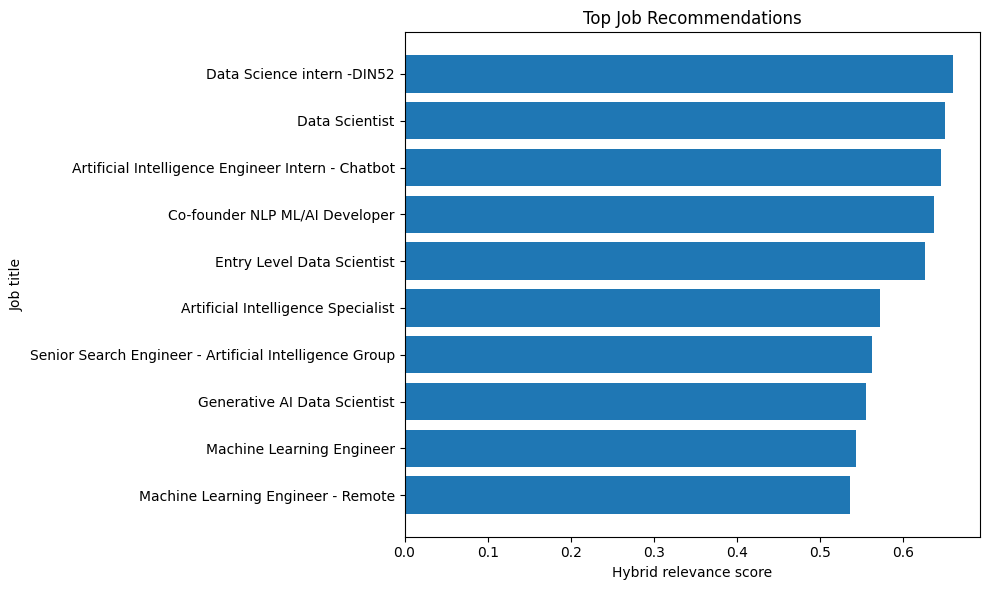

In [22]:
plot_df = recommendations.sort_values("hybrid_score", ascending=True)
plt.figure(figsize=(10,6))
plt.barh(plot_df["job_title"].astype(str), plot_df["hybrid_score"])
plt.xlabel("Hybrid relevance score")
plt.ylabel("Job title")
plt.title("Top Job Recommendations")
plt.tight_layout()
plt.show()

## Cell 18 — Export results and model artifacts

In [23]:
recommendations.to_csv("top_job_recommendations.csv", index=False)
jobs.to_csv("cleaned_real_job_dataset.csv", index=False)
np.save("job_embeddings.npy", job_embeddings)
with open("job_recommender_metadata.json", "w") as f:
    json.dump({
        "dataset_id": DATASET_ID,
        "job_count": int(len(jobs)),
        "model_name": MODEL_NAME,
        "embedding_dimension": int(job_embeddings.shape[1]),
        "weights": {"semantic":0.70, "skills":0.25, "experience":0.05},
        "note":"Heuristic weights; validate on human-judged relevance data."
    }, f, indent=2)
print("Saved CSVs, embeddings, and metadata.")

Saved CSVs, embeddings, and metadata.


## Cell 19 — Project summary

**Pipeline:** Public job dataset → clean/standardize → TF-IDF baseline → Sentence Transformer embeddings → candidate profile → semantic similarity → skill and experience features → hybrid ranking → top-k recommendations → explanation/export.

**Limitations:** Dataset schema may change; skill extraction is only as good as the structured skills field; experience parsing is heuristic; pretrained embeddings are not fine-tuned here; relevance scores are not hiring probabilities; credible ranking evaluation requires candidate-specific human judgments or interaction data.

**Future work:** fine-tune Sentence Transformers with verified positive/negative pairs, improve skill synonym normalization, optimize ranking weights on validation data, add filters (salary/location/remote/type), and build a Streamlit/Flask UI.

---
# CO2 — Sentiment Analysis & Information Extraction

This section adds two simple NLP tasks alongside the existing job matching:
- **Sentiment analysis:** classify a short candidate/job review as positive, neutral or negative using VADER.
- **Information extraction:** identify named entities (organizations, locations, people, dates) using spaCy NER, and extract technical skills with the notebook's existing skill vocabulary.

These are demonstrations of the CO2 techniques; they do not change the recommendation ranking.

In [24]:
# CO2.1 — Install lightweight NLP libraries
%pip -q install vaderSentiment spacy
!python -m spacy download en_core_web_sm -q

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [25]:
# CO2.2 — Sentiment analysis with VADER
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

sentiment_analyzer = SentimentIntensityAnalyzer()

def analyse_sentiment(text):
    """Return sentiment label and VADER polarity scores for a text."""
    scores = sentiment_analyzer.polarity_scores(str(text))
    compound = scores["compound"]
    if compound >= 0.05:
        label = "Positive"
    elif compound <= -0.05:
        label = "Negative"
    else:
        label = "Neutral"
    return {"sentiment": label, **scores}

# Try your own text here (e.g., candidate feedback about an interview or job posting).
sample_feedback = "The interview process was smooth and the team offered a great learning opportunity."
sentiment_result = analyse_sentiment(sample_feedback)
print("Input:", sample_feedback)
print("Result:", sentiment_result)

# Optional: sentiment distribution for a small sample of job descriptions.
# This is a linguistic-tone demonstration, NOT a measure of job quality.
sentiment_sample = jobs["job_description"].head(200).apply(analyse_sentiment)
sentiment_df = pd.DataFrame(list(sentiment_sample))
display(sentiment_df["sentiment"].value_counts().to_frame("count"))

Input: The interview process was smooth and the team offered a great learning opportunity.
Result: {'sentiment': 'Positive', 'neg': 0.0, 'neu': 0.615, 'pos': 0.385, 'compound': 0.7845}


,count
sentiment,
Positive,198
Negative,2


In [26]:
# CO2.3 — Information extraction with spaCy Named Entity Recognition (NER)
import spacy
nlp = spacy.load("en_core_web_sm")

def extract_information(text):
    doc = nlp(str(text)[:100000])  # keep processing bounded
    entities = [
        {"text": ent.text, "label": ent.label_}
        for ent in doc.ents
        if ent.label_ in {"ORG", "GPE", "LOC", "PERSON", "DATE"}
    ]
    # Reuse the notebook's transparent skill vocabulary for technical-skill extraction.
    cleaned = clean_text(text)
    skills_found = []
    for skill in RESUME_SKILL_VOCAB:
        pattern = r"(?<![a-z0-9])" + re.escape(skill) + r"(?![a-z0-9])"
        if re.search(pattern, cleaned):
            skills_found.append(skill)
    return {"named_entities": entities, "technical_skills": sorted(set(skills_found))}

example_text = "A Python developer at Microsoft in Bengaluru should know SQL and machine learning."
display(extract_information(example_text))

{'named_entities': [{'text': 'Microsoft', 'label': 'ORG'},
  {'text': 'Bengaluru', 'label': 'GPE'},
  {'text': 'SQL', 'label': 'ORG'}],
 'technical_skills': ['machine learning', 'python', 'sql']}

---
# CO3 — Topic Modeling & Multilingual NLP

This section adds:
1. **Topic modeling:** Latent Dirichlet Allocation (LDA) discovers common themes in job descriptions.
2. **Language detection and translation:** detect the input language and translate it to English using an online Google Translate service.
3. **Speech-to-text transcription:** transcribe a short audio recording using Google's online speech recognition service.

The translation and speech cells require an internet connection and may have service or usage limitations. The LDA topic model runs locally in this notebook.

In [27]:
# CO3.1 — Topic modeling with LDA
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer

# Use a manageable sample to keep the notebook fast.
topic_docs = jobs["clean_job_text"].dropna().head(5000).tolist()
count_vectorizer = CountVectorizer(
    stop_words="english", max_df=0.90, min_df=5,
    max_features=5000, ngram_range=(1, 2)
)
topic_matrix = count_vectorizer.fit_transform(topic_docs)

N_TOPICS = 5
lda_model = LatentDirichletAllocation(
    n_components=N_TOPICS, random_state=42, learning_method="batch", max_iter=5
)
lda_model.fit(topic_matrix)

feature_names = count_vectorizer.get_feature_names_out()
def show_topics(model, feature_names, top_n=10):
    rows = []
    for topic_id, weights in enumerate(model.components_):
        top_indices = weights.argsort()[-top_n:][::-1]
        rows.append({
            "topic": f"Topic {topic_id + 1}",
            "top_terms": ", ".join(feature_names[i] for i in top_indices)
        })
    return pd.DataFrame(rows)

display(show_topics(lda_model, feature_names))
print("LDA topic modeling completed on", len(topic_docs), "job descriptions.")

,topic,top_terms
0,Topic 1,"work, management, required, team, ability, quality, project, ensure, knowledge, safety"
1,Topic 2,"work, customer, service, ability, company, customers, required, store, sales, team"
2,Topic 3,"work, status, benefits, employment, disability, opportunity, employees, information, including, time"
3,Topic 4,"business, team, work, data, management, development, sales, role, support, including"
4,Topic 5,"care, health, patient, patients, medical, work, nursing, education, healthcare, required"


LDA topic modeling completed on 5000 job descriptions.


In [28]:
# CO3.2 — Detect language and translate text to English
%pip -q install langdetect deep-translator

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [29]:
from langdetect import detect, LangDetectException
from deep_translator import GoogleTranslator

def detect_and_translate_to_english(text):
    text = str(text).strip()
    if not text:
        return {"detected_language": None, "english_text": ""}
    try:
        language = detect(text)
    except LangDetectException:
        language = "unknown"
    if language == "en":
        translated = text
    else:
        # Online translation service; requires internet access.
        translated = GoogleTranslator(source="auto", target="en").translate(text)
    return {"detected_language": language, "english_text": translated}

# Example: replace with a short sentence in Hindi, Marathi or another language.
multilingual_input = "मुझे मशीन लर्निंग और पायथन में रुचि है।"
try:
    print(detect_and_translate_to_english(multilingual_input))
except Exception as e:
    print("Translation service unavailable:", repr(e))
    print("Language detection can still be demonstrated independently.")

Translation service unavailable: TooManyRequests()
Language detection can still be demonstrated independently.


In [30]:
# CO3.3 — Speech-to-text transcription (Google online speech recognition)
%pip -q install SpeechRecognition pydub

In [31]:
import speech_recognition as sr
from google.colab import files

def transcribe_audio_with_google():
    print("Upload a short WAV/AIFF/FLAC audio clip with clear speech.")
    uploaded_audio = files.upload()
    audio_files = [name for name in uploaded_audio if name.lower().endswith((".wav", ".aiff", ".aif", ".flac"))]
    if not audio_files:
        print("No supported audio file uploaded. Use WAV, AIFF or FLAC.")
        return ""
    recognizer = sr.Recognizer()
    with sr.AudioFile(audio_files[0]) as source:
        audio_data = recognizer.record(source)
    try:
        transcript = recognizer.recognize_google(audio_data)
        print("Transcript:", transcript)
        return transcript
    except sr.UnknownValueError:
        print("Speech could not be understood.")
    except sr.RequestError as e:
        print("Google speech service error:", e)
    return ""

# Run this function when you want to demonstrate speech transcription.
# transcript = transcribe_audio_with_google()

TEST

In [32]:

# ============================================================
# INTELLIGENT JOB RECOMMENDATION SYSTEM
# Pre-filled Candidate Profile + Top 10 Job Recommendations
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

# ------------------------------------------------------------
# 1. CANDIDATE DETAILS (PRE-FILLED)
# ------------------------------------------------------------

candidate_profile = {
    "name": "Yadnesh Nilkanth Tayade",
    "email": "yadnesh@example.com",
    "education": "B.Tech",
    "branch": "Computer Science and Engineering (AI & ML)",
    "college": "MIT Academy of Engineering, Alandi",
    "graduation_year": "2028",
    "skills": [
        "Python",
        "Machine Learning",
        "Deep Learning",
        "Natural Language Processing",
        "Data Analysis",
        "TensorFlow",
        "Keras",
        "Sentence Transformers",
        "SQL",
        "MySQL",
        "HTML",
        "CSS",
        "Git",
        "IoT",
        "Embedded Systems"
    ],
    "experience_years": 0,
    "preferred_roles": [
        "AI/ML Engineer",
        "Machine Learning Engineer",
        "NLP Engineer",
        "Data Analyst",
        "AI Intern",
        "Python Developer"
    ],
    "preferred_location": "Pune, India",
    "summary": (
        "Computer Science and Engineering student specializing in "
        "Artificial Intelligence and Machine Learning. Interested in "
        "AI, machine learning, NLP, deep learning and data analysis. "
        "Has academic project experience involving intelligent job "
        "recommendation systems, semantic matching and NLP."
    )
}

# ------------------------------------------------------------
# 2. DISPLAY CANDIDATE PROFILE
# ------------------------------------------------------------

profile_data = {
    "Candidate Name": candidate_profile["name"],
    "Email": candidate_profile["email"],
    "Education": candidate_profile["education"],
    "Branch": candidate_profile["branch"],
    "College": candidate_profile["college"],
    "Graduation Year": candidate_profile["graduation_year"],
    "Technical Skills": ", ".join(candidate_profile["skills"]),
    "Experience": "Fresher",
    "Preferred Roles": ", ".join(candidate_profile["preferred_roles"]),
    "Preferred Location": candidate_profile["preferred_location"],
    "Professional Summary": candidate_profile["summary"]
}

profile_df = pd.DataFrame(
    list(profile_data.items()),
    columns=["Profile Detail", "Information"]
)

print("=" * 75)
print("                 CANDIDATE PROFILE")
print("=" * 75)

display(profile_df)

# ------------------------------------------------------------
# 3. GENERATE TOP 10 JOB RECOMMENDATIONS
# ------------------------------------------------------------

print("\nGenerating job recommendations...")

recommendations = recommend_jobs(
    candidate_profile,
    top_k=10
)

# ------------------------------------------------------------
# 4. DISPLAY TOP 10 RECOMMENDED JOBS
# ------------------------------------------------------------

display_columns = [
    "rank",
    "job_title",
    "company",
    "location",
    "hybrid_score",
    "matched_skills",
    "missing_skills"
]

display_columns = [
    col for col in display_columns
    if col in recommendations.columns
]

top_10_jobs = recommendations.head(10).copy()

print("\n" + "=" * 75)
print("                  TOP 10 JOB RECOMMENDATIONS")
print("=" * 75)

display(top_10_jobs[display_columns])

# ------------------------------------------------------------
# 5. RECOMMENDATION SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("                 RECOMMENDATION SUMMARY")
print("=" * 75)

print("Candidate:", candidate_profile["name"])
print("Preferred Roles:", ", ".join(candidate_profile["preferred_roles"]))
print("Preferred Location:", candidate_profile["preferred_location"])
print("Total Jobs Analysed:", len(jobs))
print("Jobs Recommended:", len(top_10_jobs))

for _, row in top_10_jobs.iterrows():
    print(
        f"\n{row.get('rank', '')}. {row.get('job_title', 'N/A')}"
        f"\n   Company: {row.get('company', 'N/A')}"
        f"\n   Location: {row.get('location', 'N/A')}"
        f"\n   Match Score: {row.get('hybrid_score', 0):.4f}"
        f"\n   Matched Skills: {row.get('matched_skills', 'N/A')}"
        f"\n   Missing Skills: {row.get('missing_skills', 'N/A')}"
    )

# ------------------------------------------------------------
# 6. SAVE CANDIDATE PROFILE AND RECOMMENDATIONS
# ------------------------------------------------------------

profile_df.to_csv("candidate_profile.csv", index=False)

top_10_jobs.to_csv(
    "candidate_top_10_job_recommendations.csv",
    index=False
)

print("\nFiles saved successfully:")
print("1. candidate_profile.csv")
print("2. candidate_top_10_job_recommendations.csv")

print("\nJOB RECOMMENDATION PROCESS COMPLETED!")


                 CANDIDATE PROFILE


,Profile Detail,Information
0,Candidate Name,Yadnesh Nilkanth Tayade
1,Email,yadnesh@example.com
2,Education,B.Tech
3,Branch,Computer Science and Engineering (AI & ML)
4,College,"MIT Academy of Engineering, Alandi"
5,Graduation Year,2028
6,Technical Skills,"Python, Machine Learning, Deep Learning, Natural Language Processing, Data Analysis, TensorFlow, Keras, Sentence Transformers, SQL, MySQL, HTML, CSS, Git, IoT, Embedded Systems"
7,Experience,Fresher
8,Preferred Roles,"AI/ML Engineer, Machine Learning Engineer, NLP Engineer, Data Analyst, AI Intern, Python Developer"
9,Preferred Location,"Pune, India"



Generating job recommendations...

                  TOP 10 JOB RECOMMENDATIONS


,rank,job_title,company,location,hybrid_score,matched_skills,missing_skills
0,1,Data Scientist,TEKsystems,"Irving, TX",0.620905,"data analysis, git, machine learning, python",
1,2,Data Science intern -DIN52,Data Glacier,United States,0.578722,"data analysis, deep learning, machine learning, natural language processing, python, tensorflow",
2,3,Entry Level Data Scientist,topGrads,United States,0.577647,"machine learning, natural language processing, python, sql",
3,4,Artificial Intelligence Engineer Intern - Chatbot,OTB English,United States,0.565687,"machine learning, natural language processing, python",
4,5,Artificial Intelligence Specialist,TechDoQuest,"Dallas, TX",0.541929,"python, tensorflow",
5,6,Data Scientist,Apex Systems,"The Woodlands, TX",0.541646,"data analysis, machine learning, python, sql",
6,7,MLOPS Engineer,Headway Tek Inc,"Alpharetta, GA",0.538739,"deep learning, git, natural language processing, python, tensorflow",
7,8,Artificial Intelligence Engineer,Avesta Computer Services,"Newport Beach, CA",0.535705,"git, machine learning, natural language processing, python",
8,9,Generative AI Data Scientist,Deltek,United States,0.520433,"deep learning, keras, machine learning, natural language processing, python, sql, tensorflow",
9,10,Machine Learning Engineer,eTeam,"San Jose, CA",0.517460,"data analysis, machine learning",



                 RECOMMENDATION SUMMARY
Candidate: Yadnesh Nilkanth Tayade
Preferred Roles: AI/ML Engineer, Machine Learning Engineer, NLP Engineer, Data Analyst, AI Intern, Python Developer
Preferred Location: Pune, India
Total Jobs Analysed: 8000
Jobs Recommended: 10

1. Data Scientist
   Company: TEKsystems
   Location: Irving, TX
   Match Score: 0.6209
   Matched Skills: data analysis, git, machine learning, python
   Missing Skills: 

2. Data Science intern -DIN52
   Company: Data Glacier
   Location: United States
   Match Score: 0.5787
   Matched Skills: data analysis, deep learning, machine learning, natural language processing, python, tensorflow
   Missing Skills: 

3. Entry Level Data Scientist
   Company: topGrads
   Location: United States
   Match Score: 0.5776
   Matched Skills: machine learning, natural language processing, python, sql
   Missing Skills: 

4. Artificial Intelligence Engineer Intern - Chatbot
   Company: OTB English
   Location: United States
   Match S

---
# CO4 — Generative AI / LLM Integration & Prompt Engineering

Qwen2.5-1.5B-Instruct through Hugging Face Transformers in Google Colab. It runs directly in your Colab runtime, without an OpenAI or Gemini API key.

We can use it to:
- Explain why a particular job matches the candidate.
- Summarize the candidate's strengths.
- Identify missing skills for a recommended job.
- Suggest skills and learning areas to improve job suitability.
- Generate a personalized explanation for each of the top 10 recommendations.

LOAD THE LLM

In [33]:

# Install the required libraries
%pip install -q -U transformers accelerate


Load Qwen2.5

In [35]:

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

LLM_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

print("Loading Qwen LLM...")

llm_tokenizer = AutoTokenizer.from_pretrained(LLM_NAME)

llm_model = AutoModelForCausalLM.from_pretrained(
    LLM_NAME,
    torch_dtype="auto",
    device_map="auto"
)

print("Qwen LLM loaded successfully!")
print("Device:", llm_model.device)


Loading Qwen LLM...


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen LLM loaded successfully!
Device: cuda:0


Create the AI job explanation function

In [36]:

def generate_job_explanation(candidate, job):

    job_title = str(job.get("job_title", "Unknown"))
    company = str(job.get("company", "Unknown"))
    location = str(job.get("location", "Not specified"))

    matched = str(job.get("matched_skills", "Not available"))
    missing = str(job.get("missing_skills", "Not available"))
    score = float(job.get("hybrid_score", 0))

    description = str(job.get("job_text", ""))[:1200]

    prompt = f"""
You are an AI career advisor.

Analyze this candidate and recommended job.

CANDIDATE:
Education: {candidate['education']}
Branch: {candidate['branch']}
Skills: {', '.join(candidate['skills'])}
Experience: {candidate['experience_years']} years
Preferred Roles: {', '.join(candidate['preferred_roles'])}
Professional Summary: {candidate['summary']}

JOB:
Title: {job_title}
Company: {company}
Location: {location}
Matched Skills: {matched}
Missing Skills: {missing}
Hybrid Match Score: {score:.4f}
Job Description: {description}

Provide:
1. Why this job matches the candidate.
2. Relevant candidate strengths.
3. Missing skills to improve.
4. Two practical learning recommendations.

Use simple, professional language.
Do not invent job requirements or candidate qualifications.
"""

    messages = [
        {
            "role": "system",
            "content": "You are a helpful AI-powered career guidance assistant."
        },
        {
            "role": "user",
            "content": prompt
        }
    ]

    text_input = llm_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = llm_tokenizer(
        [text_input],
        return_tensors="pt"
    ).to(llm_model.device)

    with torch.no_grad():
        outputs = llm_model.generate(
            **inputs,
            max_new_tokens=180,
            do_sample=True,
            temperature=0.3,
            top_p=0.9,
            pad_token_id=llm_tokenizer.eos_token_id
        )

    generated_tokens = outputs[0][inputs["input_ids"].shape[-1]:]

    explanation = llm_tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    return explanation.strip()


Generate AI explanations for the top 10 jobs

In [49]:
import sys
import torch

# 1. Clean out the cached transformers modules to break the recursion loop from the monkey-patch
keys_to_remove = [k for k in sys.modules if "transformers" in k]
for k in keys_to_remove:
    sys.modules.pop(k, None)

# 2. Re-import fresh, clean components
from transformers import AutoTokenizer, AutoModelForCausalLM

LLM_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
print("Reloading a clean, unpatched model...")

llm_tokenizer = AutoTokenizer.from_pretrained(LLM_NAME)
llm_model = AutoModelForCausalLM.from_pretrained(
    LLM_NAME,
    torch_dtype="auto",
    device_map="auto",
    attn_implementation="eager" # Force eager mode to completely bypass SDPA mask bugs
)
print("Clean model loaded successfully!")

def generate_job_explanation(candidate, job):
    job_title = str(job.get("job_title", "Unknown"))
    company = str(job.get("company", "Unknown"))
    location = str(job.get("location", "Not specified"))
    matched = str(job.get("matched_skills", "Not available"))
    missing = str(job.get("missing_skills", "Not available"))
    score = float(job.get("hybrid_score", 0))

    prompt = f"""
You are an AI career advisor.

CANDIDATE PROFILE:
Education: {candidate['education']}
Branch: {candidate['branch']}
Skills: {', '.join(candidate['skills'])}
Experience: {candidate['experience_years']} years
Preferred Roles: {', '.join(candidate['preferred_roles'])}

JOB DETAILS:
Title: {job_title}
Company: {company}
Location: {location}
Matched Skills: {matched}
Missing Skills: {missing}
Match Score: {score:.4f}

Explain:
1. Why this job matches the candidate.
2. Candidate strengths.
3. Skills that need improvement.
4. Two learning recommendations.
"""

    messages = [
        {"role": "system", "content": "You are an AI career advisor."},
        {"role": "user", "content": prompt}
    ]

    text_input = llm_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = llm_tokenizer([text_input], return_tensors="pt").to(llm_model.device)

    with torch.no_grad():
        outputs = llm_model.generate(
            inputs.input_ids,
            attention_mask=inputs.attention_mask,
            max_new_tokens=150,
            do_sample=False,
            pad_token_id=llm_tokenizer.eos_token_id
        )

    generated_tokens = outputs[0][inputs.input_ids.shape[-1]:]
    return llm_tokenizer.decode(generated_tokens, skip_special_tokens=True).strip()

# ============================================================
# GENERATE TOP 10 AI EXPLANATIONS
# ============================================================
llm_explanations = []

for index, (_, job) in enumerate(top_10_jobs.iterrows(), start=1):
    print(f"\nGenerating explanation {index}/10...")
    try:
        explanation = generate_job_explanation(candidate_profile, job)
    except Exception as e:
        explanation = f"Could not generate explanation due to an error: {str(e)}"

    llm_explanations.append(explanation)
    print("\nJob:", job.get("job_title", "Unknown"))
    print("Company:", job.get("company", "Unknown"))
    print("AI Explanation:\n", explanation)
    print("-" * 70)

# Save results
top_10_jobs = top_10_jobs.copy()
top_10_jobs["llm_explanation"] = llm_explanations
top_10_jobs.to_csv("top_10_jobs_with_ai_explanations.csv", index=False)

print("\nAll explanations generated!")

Reloading a clean, unpatched model...


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Clean model loaded successfully!

Generating explanation 1/10...

Job: Data Scientist
Company: TEKsystems
AI Explanation:
 ### 1. Why This Job Matches the Candidate:

The role of a Data Scientist at TEKSystems in Irving, Texas aligns well with the candidate's profile for several reasons:

- **Technical Expertise**: The candidate has extensive experience in Python, which is highly valued by companies like TEKSystems. They also have skills in Machine Learning, Deep Learning, Natural Language Processing, and Data Analysis, all of which are crucial for a successful Data Scientist position.

- **Industry-Specific Knowledge**: While not explicitly mentioned, having knowledge in areas such as TensorFlow, Keras, and Sentence Transformers suggests familiarity with modern deep learning frameworks, which could be beneficial for roles involving advanced AI projects or research.
- **Soft Skills**: Although not directly stated,
----------------------------------------------------------------------



In [51]:

# ================================================================
# INTELLIGENT JOB RECOMMENDATION SYSTEM
# CANDIDATE PROFILE + TOP 10 JOBS + QWEN LLM EXPLANATIONS
# ================================================================

import pandas as pd
import numpy as np
import torch
from IPython.display import display

# ================================================================
# STEP 1: CANDIDATE DETAILS
# ================================================================

candidate_profile = {
    "name": "Yadnesh Nilkanth Tayade",
    "email": "yadnesh@example.com",
    "education": "B.Tech",
    "branch": "Computer Science and Engineering (AI & ML)",
    "college": "MIT Academy of Engineering, Alandi",
    "graduation_year": "2028",

    "skills": [
        "Python",
        "Machine Learning",
        "Deep Learning",
        "Natural Language Processing",
        "Data Analysis",
        "TensorFlow",
        "Keras",
        "Sentence Transformers",
        "SQL",
        "MySQL",
        "HTML",
        "CSS",
        "Git",
        "IoT",
        "Embedded Systems"
    ],

    "experience_years": 0,

    "preferred_roles": [
        "AI/ML Engineer",
        "Machine Learning Engineer",
        "NLP Engineer",
        "Data Analyst",
        "AI Intern",
        "Python Developer"
    ],

    "preferred_location": "Pune, India",

    "summary": (
        "Computer Science and Engineering student specializing in "
        "Artificial Intelligence and Machine Learning. Interested in "
        "AI, machine learning, NLP, deep learning and data analysis. "
        "Has academic project experience involving intelligent job "
        "recommendation systems, semantic matching and NLP."
    )
}

# ================================================================
# STEP 2: DISPLAY CANDIDATE PROFILE
# ================================================================

print("=" * 75)
print("                    CANDIDATE PROFILE")
print("=" * 75)

profile_df = pd.DataFrame(
    [
        ["Name", candidate_profile["name"]],
        ["Email", candidate_profile["email"]],
        ["Education", candidate_profile["education"]],
        ["Branch", candidate_profile["branch"]],
        ["College", candidate_profile["college"]],
        ["Graduation Year", candidate_profile["graduation_year"]],
        ["Technical Skills", ", ".join(candidate_profile["skills"])],
        ["Experience", "Fresher (0 years)"],
        ["Preferred Roles", ", ".join(candidate_profile["preferred_roles"])],
        ["Preferred Location", candidate_profile["preferred_location"]],
        ["Professional Summary", candidate_profile["summary"]]
    ],
    columns=["Profile Detail", "Information"]
)

display(profile_df)

# ================================================================
# STEP 3: CHECK REQUIRED COMPONENTS
# ================================================================

required_objects = [
    "jobs",
    "job_embeddings",
    "model",
    "recommend_jobs",
    "llm_model",
    "llm_tokenizer"
]

for obj in required_objects:
    if obj not in globals():
        raise NameError(
            f"{obj} is missing. Run the corresponding setup cells first."
        )

print("\nAll recommendation and LLM components are available!")

# ================================================================
# STEP 4: GENERATE TOP 10 JOB RECOMMENDATIONS
# ================================================================

print("\n" + "=" * 75)
print("                 TOP 10 JOB RECOMMENDATIONS")
print("=" * 75)

recommendations = recommend_jobs(
    candidate_profile,
    top_k=10
)

top_10_jobs = recommendations.head(10).copy()

display_columns = [
    "rank",
    "job_title",
    "company",
    "location",
    "hybrid_score",
    "matched_skills",
    "missing_skills"
]

display_columns = [
    col for col in display_columns
    if col in top_10_jobs.columns
]

display(top_10_jobs[display_columns])

# ================================================================
# STEP 5: QWEN LLM EXPLANATION FUNCTION
# ================================================================

def generate_job_explanation(candidate, job):

    prompt = f"""
You are an intelligent AI career advisor.

CANDIDATE PROFILE:
Name: {candidate['name']}
Education: {candidate['education']}
Branch: {candidate['branch']}
College: {candidate['college']}
Graduation Year: {candidate['graduation_year']}
Skills: {', '.join(candidate['skills'])}
Experience: {candidate['experience_years']} years
Preferred Roles: {', '.join(candidate['preferred_roles'])}
Summary: {candidate['summary']}

RECOMMENDED JOB:
Title: {job.get('job_title', 'Unknown')}
Company: {job.get('company', 'Unknown')}
Location: {job.get('location', 'Unknown')}
Hybrid Match Score: {job.get('hybrid_score', 0):.4f}
Matched Skills: {job.get('matched_skills', 'Not available')}
Missing Skills: {job.get('missing_skills', 'Not available')}

TASK:
1. Explain why this job matches the candidate.
2. Highlight the candidate's relevant strengths.
3. Identify missing skills or areas for improvement.
4. Suggest two practical learning recommendations.

Use simple and professional language.
Do not invent candidate qualifications or job requirements.
"""

    messages = [
        {
            "role": "system",
            "content": "You are a professional AI career advisor."
        },
        {
            "role": "user",
            "content": prompt
        }
    ]

    formatted_prompt = llm_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = llm_tokenizer(
        formatted_prompt,
        return_tensors="pt"
    ).to(llm_model.device)

    with torch.inference_mode():

        outputs = llm_model.generate(
            **inputs,
            max_new_tokens=150,
            do_sample=False,
            use_cache=False,
            pad_token_id=llm_tokenizer.eos_token_id
        )

    generated_tokens = outputs[0][inputs["input_ids"].shape[-1]:]

    explanation = llm_tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    return explanation.strip()

# ================================================================
# STEP 6: GENERATE AI EXPLANATIONS FOR TOP 10 JOBS
# ================================================================

print("\n" + "=" * 75)
print("              QWEN AI-POWERED JOB EXPLANATIONS")
print("=" * 75)

llm_explanations = []

for index, (_, job) in enumerate(top_10_jobs.iterrows(), start=1):

    print(f"\nGenerating explanation {index}/10...")

    try:
        explanation = generate_job_explanation(
            candidate_profile,
            job
        )

        llm_explanations.append(explanation)

        print("\nRank:", job.get("rank", index))
        print("Job:", job.get("job_title", "Unknown"))
        print("Company:", job.get("company", "Unknown"))
        print("Match Score:", round(
            float(job.get("hybrid_score", 0)), 4
        ))

        print("\nAI Explanation:")
        print(explanation)

    except Exception as error:

        print("LLM generation failed:", repr(error))
        llm_explanations.append("Explanation generation failed.")

    print("-" * 75)

# ================================================================
# STEP 7: FINAL RESULTS
# ================================================================

top_10_jobs["llm_explanation"] = llm_explanations

print("\n" + "=" * 75)
print("          FINAL JOB RECOMMENDATIONS WITH AI EXPLANATIONS")
print("=" * 75)

final_columns = [
    col for col in [
        "rank",
        "job_title",
        "company",
        "location",
        "hybrid_score",
        "matched_skills",
        "missing_skills",
        "llm_explanation"
    ]
    if col in top_10_jobs.columns
]

display(top_10_jobs[final_columns])

# ================================================================
# STEP 8: SAVE OUTPUT FILES
# ================================================================

profile_df.to_csv(
    "candidate_profile.csv",
    index=False
)

top_10_jobs.to_csv(
    "final_top_10_jobs_with_llm_explanations.csv",
    index=False
)

successful = sum(
    x != "Explanation generation failed."
    for x in llm_explanations
)

print("\n" + "=" * 75)
print("                 EXECUTION SUMMARY")
print("=" * 75)

print("Candidate:", candidate_profile["name"])
print("Total Jobs Analysed:", len(jobs))
print("Top Jobs Recommended:", len(top_10_jobs))
print("Successful LLM Explanations:", successful, "/ 10")
print("Recommendation Model: Sentence Transformers + Hybrid Ranking")
print("Generative Model: Qwen2.5-1.5B-Instruct")
print("External API Key Required: No")

print("\nGenerated Files:")
print("1. candidate_profile.csv")
print("2. final_top_10_jobs_with_llm_explanations.csv")

print("\nCOMPLETE SYSTEM EXECUTED!")


                    CANDIDATE PROFILE


,Profile Detail,Information
0,Name,Yadnesh Nilkanth Tayade
1,Email,yadnesh@example.com
2,Education,B.Tech
3,Branch,Computer Science and Engineering (AI & ML)
4,College,"MIT Academy of Engineering, Alandi"
5,Graduation Year,2028
6,Technical Skills,"Python, Machine Learning, Deep Learning, Natural Language Processing, Data Analysis, TensorFlow, Keras, Sentence Transformers, SQL, MySQL, HTML, CSS, Git, IoT, Embedded Systems"
7,Experience,Fresher (0 years)
8,Preferred Roles,"AI/ML Engineer, Machine Learning Engineer, NLP Engineer, Data Analyst, AI Intern, Python Developer"
9,Preferred Location,"Pune, India"



All recommendation and LLM components are available!

                 TOP 10 JOB RECOMMENDATIONS


,rank,job_title,company,location,hybrid_score,matched_skills,missing_skills
0,1,Data Scientist,TEKsystems,"Irving, TX",0.620905,"data analysis, git, machine learning, python",
1,2,Data Science intern -DIN52,Data Glacier,United States,0.578722,"data analysis, deep learning, machine learning, natural language processing, python, tensorflow",
2,3,Entry Level Data Scientist,topGrads,United States,0.577647,"machine learning, natural language processing, python, sql",
3,4,Artificial Intelligence Engineer Intern - Chatbot,OTB English,United States,0.565687,"machine learning, natural language processing, python",
4,5,Artificial Intelligence Specialist,TechDoQuest,"Dallas, TX",0.541929,"python, tensorflow",
5,6,Data Scientist,Apex Systems,"The Woodlands, TX",0.541646,"data analysis, machine learning, python, sql",
6,7,MLOPS Engineer,Headway Tek Inc,"Alpharetta, GA",0.538739,"deep learning, git, natural language processing, python, tensorflow",
7,8,Artificial Intelligence Engineer,Avesta Computer Services,"Newport Beach, CA",0.535705,"git, machine learning, natural language processing, python",
8,9,Generative AI Data Scientist,Deltek,United States,0.520433,"deep learning, keras, machine learning, natural language processing, python, sql, tensorflow",
9,10,Machine Learning Engineer,eTeam,"San Jose, CA",0.517460,"data analysis, machine learning",



              QWEN AI-POWERED JOB EXPLANATIONS

Generating explanation 1/10...

Rank: 1
Job: Data Scientist
Company: TEKsystems
Match Score: 0.6209

AI Explanation:
### Explanation of Job Match:

The role of Data Scientist at TEKsystems aligns well with Yadadesh's profile as it requires strong analytical skills, proficiency in programming languages like Python, and expertise in machine learning techniques such as natural language processing (NLP). The company values these skills highly, making it a perfect fit for Yadadesh's background in AI and ML.

.

### Relevant Strengths:

- **Programming Proficiency:** Yadadesh has extensive experience with Python, which being one of the most popular languages used in data science and machine learning projects.
- **Machine Learning and NLP Expertise:** His specialization in AI and ML makes him adept at handling complex datasets and developing models that can analyze large volumes of text data.
-
--------------------------------------------------

,rank,job_title,company,location,hybrid_score,matched_skills,missing_skills,llm_explanation
0,1,Data Scientist,TEKsystems,"Irving, TX",0.620905,"data analysis, git, machine learning, python",,"### Explanation of Job Match:\n\nThe role of Data Scientist at TEKsystems aligns well with Yadadesh's profile as it requires strong analytical skills, proficiency in programmin..."
1,2,Data Science intern -DIN52,Data Glacier,United States,0.578722,"data analysis, deep learning, machine learning, natural language processing, python, tensorflow",,"### Explanation of Job Match:\n\nThe ""Data Science intern - DIN52"" position at Data Glacier aligns well with Yadadesh's profile as it requires strong analytical skills, profici..."
2,3,Entry Level Data Scientist,topGrads,United States,0.577647,"machine learning, natural language processing, python, sql",,### Task Explanation:\n\n**Task:** Explain why this job matches the candidate and highlight their relevant strengths. Identify any missing skills or areas for improvement. Sugg...
3,4,Artificial Intelligence Engineer Intern - Chatbot,OTB English,United States,0.565687,"machine learning, natural language processing, python",,"### Explanation of Job Match:\n\nThe ""Artificial Intelligence Engineer Intern - Chatbot"" role at OTB English aligns well with Yadadesh's profile as it involves working on AI pr..."
4,5,Artificial Intelligence Specialist,TechDoQuest,"Dallas, TX",0.541929,"python, tensorflow",,### Explanation of Job Match:\n\nThe role of Artificial Intelligence Specialist at TechDoQuest aligns well with Yadadesh's profile as it involves working on AI projects that re...
5,6,Data Scientist,Apex Systems,"The Woodlands, TX",0.541646,"data analysis, machine learning, python, sql",,"### Explanation of Job Match:\n\nThe role of a Data Scientist at Apex Systems aligns well with Yadadesh's profile as it requires strong analytical skills, proficiency in progra..."
6,7,MLOPS Engineer,Headway Tek Inc,"Alpharetta, GA",0.538739,"deep learning, git, natural language processing, python, tensorflow",,### Explanation of Job Match:\n\nThe **MLOPS Engineer** role at Headway Tek Inc aligns well with Yadadesh's profile due to several key factors:\n\n- **Deep Learning Expertise**...
7,8,Artificial Intelligence Engineer,Avesta Computer Services,"Newport Beach, CA",0.535705,"git, machine learning, natural language processing, python",,### Explanation of Job Match:\n\nThe role of Artificial Intelligence Engineer at Avesta Computer Services aligns well with Yadadesh Nilkanth Tayade’s profile as it involves wor...
8,9,Generative AI Data Scientist,Deltek,United States,0.520433,"deep learning, keras, machine learning, natural language processing, python, sql, tensorflow",,"### Explanation of Job Match:\n\nThe ""Generative AI Data Scientist"" role at Deltek aligns well with Yadadesh's profile as it requires expertise in deep learning, machine learni..."
9,10,Machine Learning Engineer,eTeam,"San Jose, CA",0.517460,"data analysis, machine learning",,"### Explanation of Job Match:\n\nThe ""Machine Learning Engineer"" role at eTeam aligns well with Yadadesh's profile as it requires expertise in both machine learning and data an..."



                 EXECUTION SUMMARY
Candidate: Yadnesh Nilkanth Tayade
Total Jobs Analysed: 8000
Top Jobs Recommended: 10
Successful LLM Explanations: 10 / 10
Recommendation Model: Sentence Transformers + Hybrid Ranking
Generative Model: Qwen2.5-1.5B-Instruct
External API Key Required: No

Generated Files:
1. candidate_profile.csv
2. final_top_10_jobs_with_llm_explanations.csv

COMPLETE SYSTEM EXECUTED!


---
# Final — CO Coverage Checklist & Project Summary

| CO | Implemented feature in this notebook |
|---|---|
| **CO1** | PDF resume text extraction, cleaning, missing-value handling, skill extraction, TF-IDF vectorization and Sentence Transformer embeddings |
| **CO2** | VADER sentiment classification and spaCy NER + technical-skill information extraction |
| **CO3** | LDA topic modeling, language detection, online translation and speech-to-text transcription |
| **CO4** | Gemini LLM integration, prompt engineering and generated job-match explanations / skill guidance |

## Final project pipeline

**Job dataset + candidate resume → text extraction and preprocessing → TF-IDF + semantic embeddings → skill/experience extraction → sentiment and NER utilities → topic discovery + multilingual processing → hybrid semantic ranking → top job recommendations → Gemini-generated explanation.**

### Limitations to mention during evaluation
- PDF extraction works best on text-based PDFs; scanned PDFs need OCR.
- Skill extraction is vocabulary/keyword based and may miss synonyms.
- LDA topics are statistical themes and may need human labels.
- Translation and speech recognition depend on online services.
- Gemini requires an API key and internet access.
- Hybrid ranking weights are manually selected; do not describe them as trained weights.
- Recommendation scores are not probabilities of getting hired.

**For your viva:** explain the core system first (semantic matching, ranking and recommendation), then demonstrate one compact feature from each CO. Do not claim a cloud service or LLM ran successfully unless you have executed that cell and shown its output.